## Lab
- You submit an .ipynb or .py that does two things:
    1. Determines an optimal price algorithmically (your code searches for and discovers an optimal price)
    2. Tracks the total number of consumers you have experimented with (at the optimum, each consumer has an expected profit of $11.925)

- The optimal price is between 0 and 70: There is no reason to consider prices outside that range
- There are multiple prices that appear optimal, but only one is globally optimal

- Provide a 1-3 page write-up explaining your design, including tables and plots as necessary:
    1. A one-paragraph summary of the problem
    2. Two paragraphs about how your design handles uncertainty about changes in revenue and selects prices
    3. Two paragraphs about challenges you faced and how you resolved them
    4. One paragraph that summarizes your results. In particular, how many consumers did you experiment on, what were your revenues during the experiments, and what percentage of the optimal profit ($11.925 per customer) did you capture?


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

rng = np.random.default_rng(100)

## Defining the base functions

In [2]:
# Function which gives probability of purchase based on price
def purchase_probability(price):
    price = np.asarray(price, dtype=float)
    return (
        0.55 * np.exp(-np.logaddexp(0.0, (price - 13.9) / 0.8))
        + 0.30 * np.exp(-np.logaddexp(0.0, (price - 30.9) / 1.2))
        + 0.15 * np.exp(-np.logaddexp(0.0, (price - 58.4) / 1.8))
    )

In [3]:
# Very important and base function
# Functions that gives an array of 0s and 1s showing how many people made a purchase.
def sales(price=14.0, rng=None, mean_customers=30):
    price = float(price)
    if not np.isfinite(price):
        raise ValueError("price must be finite")
    if price < 0:
        raise ValueError("price must be nonnegative")
    mean_customers = float(mean_customers)
    if not np.isfinite(mean_customers) or mean_customers < 0:
        raise ValueError("mean_customers must be finite and nonnegative")
    rng = np.random.default_rng(rng)
    customer_count = rng.poisson(mean_customers) #Random number from poisson distribution
    probability = purchase_probability(price)
    return rng.binomial(1, probability, size=customer_count).astype(np.int8)

In [4]:
# Gradient function that calculates revenue in a small change in price to suggest if
# we should increase the price or decrease it
# A positive slope suggests raising the price; a negative slope suggests lowering it.
def estimate_gradient(price, *, step=1.0, mean_customers=300, rng=None):
    if step <= 0:
        raise ValueError("step must be positive")
    rng = np.random.default_rng(rng)
    price = float(np.clip(price, 0, 75))
    price_low = max(0, price - step)
    price_high = min(75, price + step)
    low = price_low * sales(price_low, mean_customers=mean_customers, rng=rng)
    high = price_high * sales(price_high, mean_customers=mean_customers, rng=rng)
    if min(len(low), len(high)) < 2:
        raise ValueError("Need at least two customers per arm; increase mean_customers.")

    difference = high.mean() - low.mean()
    se = np.sqrt(low.var(ddof=1) / len(low) + high.var(ddof=1) / len(high))
    gap = price_high - price_low
    return {
        "price": price,
        "gradient": difference / gap,
        "gradient_se": se / gap,
        "ci_low": (difference - 1.96 * se) / gap,
        "ci_high": (difference + 1.96 * se) / gap,
        "customers": len(low) + len(high),
        "revenue": low.sum() + high.sum()
    }

In [5]:
# Let the gradient function learn and progress itself towards the optimum price.
def gradient_ascent(start_price, iterations=80, step=1.0,
                    learning_rate=2.0, mean_customers=300, seed=100):
    if iterations < 1:
        raise ValueError("iterations must be at least 1")
    search_rng = np.random.default_rng(seed)
    price = float(np.clip(start_price, 0, 75))
    records = []
    for iteration in range(iterations):
        estimate = estimate_gradient(price, step=step,
                                     mean_customers=mean_customers, rng=search_rng)
        rate = learning_rate / np.sqrt(iteration + 1)
        move = np.clip(rate * estimate["gradient"], -2.0, 2.0)
        next_price = float(np.clip(price + move, 0, 75))
        records.append({"iteration": iteration + 1, **estimate,
                        "learning_rate": rate, "next_price": next_price})
        price = next_price
    return pd.DataFrame(records)

In [6]:
total_customers = 0  # running count to measure overall customers
total_revenue = 0.0  # running total to measure the total revenue.

## Step 1 : Coarse grid search
>- Doing coarse grid search over the whole range 0-70 with small increments of 2.
>- To understand the distribution of revenue.
>- We will plot the CIs with the means and standard deviations for all the prices.
>- And eliminate prics that are clearly producing low revenues.

In [7]:
data = {}

for i in range(0, 71, 2):
    revenue = sales(i, rng=rng, mean_customers=100) * i  # revenue from each customer, sample array [2,0,2,2,2,0]
    data[i] = list(revenue)
    total_customers += len(revenue)
    total_revenue += revenue.sum()

raw_data = pd.DataFrame({d: pd.Series(data[d]) for d in data})

total = pd.DataFrame({
    "Total customers": raw_data.count(), 
    "Total revenue": raw_data.sum(),
}).T

raw_data_with_totals = pd.concat([raw_data, total])
display(raw_data_with_totals)

,0,2,4,6,8,10,12,14,16,18,...,52,54,56,58,60,62,64,66,68,70
0,0.0,2.0,4.0,6.0,8.0,10.0,12.0,14.0,16.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,2.0,4.0,6.0,8.0,10.0,12.0,0.0,16.0,18.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,2.0,4.0,6.0,8.0,10.0,12.0,14.0,16.0,0.0,...,0.0,0.0,0.0,58.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,2.0,4.0,6.0,8.0,10.0,12.0,14.0,0.0,18.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,2.0,4.0,6.0,8.0,10.0,12.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
120,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN
121,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN
122,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN
Total customers,111.0,108.0,101.0,109.0,98.0,101.0,111.0,95.0,120.0,108.0,...,91.0,106.0,90.0,108.0,100.0,123.0,104.0,93.0,98.0,90.0


Summary of each coarse price:


,0,1,2,3,4,5,6,7,8,9,...,26,27,28,29,30,31,32,33,34,35
price,0.0,2.0,4.0,6.0,8.0,10.0,12.000,14.000,16.000,18.000,...,52.000,54.000,56.000,58.000,60.000,62.000,64.000,66.0,68.0,70.0
customers,111.0,108.0,101.0,109.0,98.0,101.0,111.000,95.000,120.000,108.000,...,91.000,106.000,90.000,108.000,100.000,123.000,104.000,93.0,98.0,90.0
buyers,0.0,108.0,101.0,109.0,98.0,101.0,107.000,61.000,55.000,52.000,...,8.000,12.000,12.000,11.000,5.000,1.000,1.000,0.0,0.0,0.0
mean,0.0,2.0,4.0,6.0,8.0,10.0,11.568,8.989,7.333,8.667,...,4.571,6.113,7.467,5.907,3.000,0.504,0.615,0.0,0.0,0.0
se,0.0,0.0,0.0,0.0,0.0,0.0,0.213,0.692,0.731,0.869,...,1.552,1.670,2.018,1.696,1.314,0.504,0.615,0.0,0.0,0.0


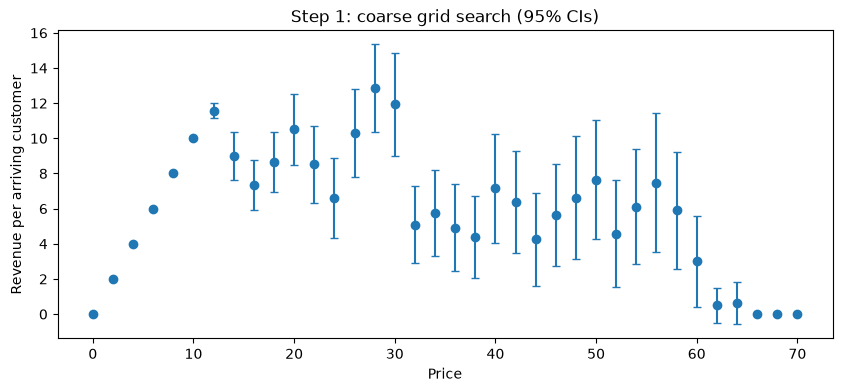

In [8]:
# Mean revenue per customer and 95% confidence interval
coarse_prices = list(data.keys())
means = [np.mean(data[p]) for p in coarse_prices]
ses = [np.std(data[p], ddof=1) / np.sqrt(len(data[p])) for p in coarse_prices]

# Show coarse_prices, means and ses side by side
coarse_table = pd.DataFrame({
    "price": coarse_prices,
    "customers": [len(data[p]) for p in coarse_prices],
    "buyers": [np.count_nonzero(data[p]) for p in coarse_prices],
    "mean": means,
    "se": ses,
}).T
print("Summary of each coarse price:")
display(coarse_table.round(3))

plt.figure(figsize=(10, 4))
plt.errorbar(coarse_prices, means, yerr=1.96 * np.array(ses), fmt="o", capsize=3)
plt.xlabel("Price")
plt.ylabel("Revenue per arriving customer")
plt.title("Step 1: coarse grid search (95% CIs)")
plt.show()

In [9]:
print(f"Customers used so far: {total_customers}")
print(f"Revenue so far: ${total_revenue:,.2f}")

Customers used so far: 3676
Revenue so far: $21,852.00


## Step 2: Dropping clearly poor prices.
>- We keep the prices whose best revenue (upper bound) is atleast as high as the best of the worst revenues (best lower bound of all).
>- For example, if the best lower bound is $10 revenue per customer. If an interval whose upper bound is even lower than that , it means overall that price can not give better revenue per customer than the lowest revenue of some other price.
>- Hence, we drop those kind of prices.

In [10]:
lows = np.array(means) - 1.96 * np.array(ses)
highs = np.array(means) + 1.96 * np.array(ses)
promising_prices = []

for i in range(len(coarse_prices)):
    if highs[i] >= lows.max():
        promising_prices.append(coarse_prices[i])

print(f"Best lower bound: {lows.max():.3f}")
print(f"Promising coarse prices: {promising_prices}")

Best lower bound: 11.150
Promising coarse prices: [12, 20, 26, 28, 30, 56]


## Step 3: Test the promising prices with a bigger batch
>- We give every promising price a bigger batch of customers (500 more each), which makes its confidence interval narrower.
>- The promising price with the highest mean is chosen as the best price.

,price,customers,mean,se,low,high
0,12,633,11.602,0.085,11.434,11.769
1,20,608,9.375,0.405,8.581,10.169
2,26,598,12.043,0.531,11.003,13.083
3,28,603,11.609,0.562,10.507,12.711
4,30,583,10.292,0.590,9.135,11.449
5,56,615,6.374,0.718,4.967,7.781


Best price (highest mean): $26


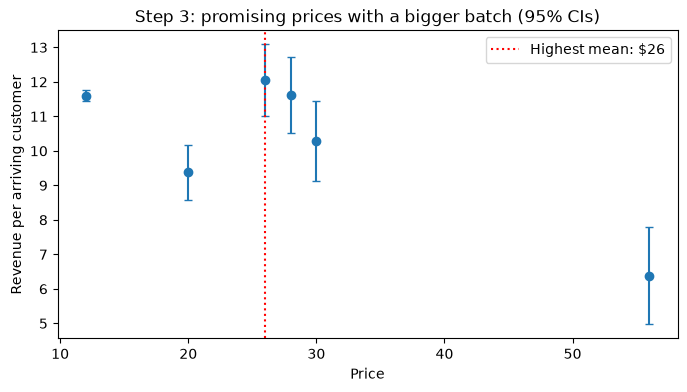

Customers used so far: 6699
Revenue so far: $52,284.00


In [11]:
batch = 500
for p in promising_prices:
    revenue = sales(p, mean_customers=batch, rng=rng) * p
    data[p].extend(revenue)  # add the new customers to the ones we already have
    total_customers += len(revenue)
    total_revenue += revenue.sum()

# 95% confidence interval for every promising price, now with more customers
means2 = np.array([np.mean(data[p]) for p in promising_prices])
ses2 = np.array([np.std(data[p], ddof=1) / np.sqrt(len(data[p])) for p in promising_prices])
lows2 = means2 - 1.96 * ses2
highs2 = means2 + 1.96 * ses2

# Show means2, ses2, lows2 and highs2 for every promising price
promising_table = pd.DataFrame({
    "price": promising_prices,
    "customers": [len(data[p]) for p in promising_prices],
    "mean": means2,
    "se": ses2,
    "low": lows2,
    "high": highs2,
})
display(promising_table.round(3))

# The promising price with the highest mean is our best price
best_price = promising_prices[0]
for p in promising_prices:
    if np.mean(data[p]) > np.mean(data[best_price]):
        best_price = p
print(f"Best price (highest mean): ${best_price}")

plt.figure(figsize=(8, 4))
plt.errorbar(promising_prices, means2, yerr=1.96 * ses2, fmt="o", capsize=3)
plt.axvline(best_price, color="red", linestyle=":", label=f"Highest mean: ${best_price}")
plt.xlabel("Price")
plt.ylabel("Revenue per arriving customer")
plt.title("Step 3: promising prices with a bigger batch (95% CIs)")
plt.legend()
plt.show()

print(f"Customers used so far: {total_customers}")
print(f"Revenue so far: ${total_revenue:,.2f}")

## Step 4 : Fine-tune the price with gradient ascent
>- We start gradient_ascent from the best whole-dollar price. 
>- Since we already know this is the best peak, the local search cannot get stuck on a worse one.

In [12]:
path = gradient_ascent(best_price, iterations=25, step=1.0,
                       learning_rate=2.0, mean_customers=200, seed=100)
print("Every iteration of gradient ascent:")
display(path.round(3))

# Each gradient step is noisy, so we average the prices from the last 5
# iterations instead of trusting only the very last one.
optimal_price = round(path["next_price"].tail(5).mean(), 2)
print(f"Last 5 prices: {list(path['next_price'].tail(5).round(2))}")
print(f"Optimal price found (their average): ${optimal_price:.2f}")

Every iteration of gradient ascent:


,iteration,price,gradient,gradient_se,ci_low,ci_high,customers,revenue,learning_rate,next_price
0,1,26.000,0.384,0.665,-0.919,1.687,392,5126.000,2.000,26.769
1,2,26.769,0.480,0.663,-0.819,1.779,408,4808.333,1.414,27.447
2,3,27.447,1.006,0.673,-0.313,2.326,415,5220.992,1.155,28.609
3,4,28.609,2.314,0.695,0.952,3.676,386,3944.487,1.000,30.609
4,5,30.609,-1.253,0.709,-2.644,0.137,374,3171.377,0.894,29.488
5,6,29.488,-0.774,0.699,-2.144,0.596,410,4354.278,0.816,28.856
6,7,28.856,-0.181,0.700,-1.554,1.191,397,4236.905,0.756,28.719
7,8,28.719,-0.029,0.716,-1.432,1.373,388,4450.503,0.707,28.699
8,9,28.699,-0.933,0.731,-2.365,0.499,386,5044.661,0.667,28.077
9,10,28.077,-0.266,0.682,-1.602,1.071,416,4991.655,0.632,27.909


Last 5 prices: [27.72, 27.74, 27.49, 28.01, 28.04]
Optimal price found (their average): $27.80


Slope check at the chosen price:


,price,gradient,gradient_se,ci_low,ci_high,customers,revenue
0,27.8,-0.486,0.304,-1.081,0.109,2020,23003.2


Step 4 customers: 11870, Step 4 revenue: $136,976.92


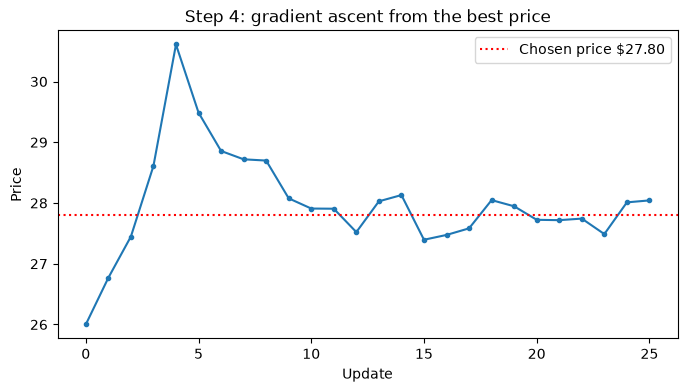

In [13]:
# At the top of the curve the slope should be about 0, so the 95% CI of the slope should contain 0.
check = estimate_gradient(optimal_price, step=1.0, mean_customers=1000, rng=rng)
print("Slope check at the chosen price:")
display(pd.DataFrame([check]).round(3))


local_customers = path["customers"].sum() + check["customers"]
local_revenue = path["revenue"].sum() + check["revenue"]
total_customers += local_customers
total_revenue += local_revenue
print(f"Step 4 customers: {local_customers}, Step 4 revenue: ${local_revenue:,.2f}")

plt.figure(figsize=(8, 4))
plt.plot(range(len(path) + 1), [best_price] + list(path["next_price"]), marker=".")
plt.axhline(optimal_price, color="red", linestyle=":", label=f"Chosen price ${optimal_price:.2f}")
plt.xlabel("Update")
plt.ylabel("Price")
plt.title("Step 4: gradient ascent from the best price")
plt.legend()
plt.show()

## Step 5: Final results

Optimal price found:              $27.80
Total customers experimented on:  18,569
Total revenue during experiments: $189,260.92
Revenue per customer:             $10.192
Share of optimal profit captured: 85.5%
True expected revenue at $27.80: 11.924 (99.99% of optimal)


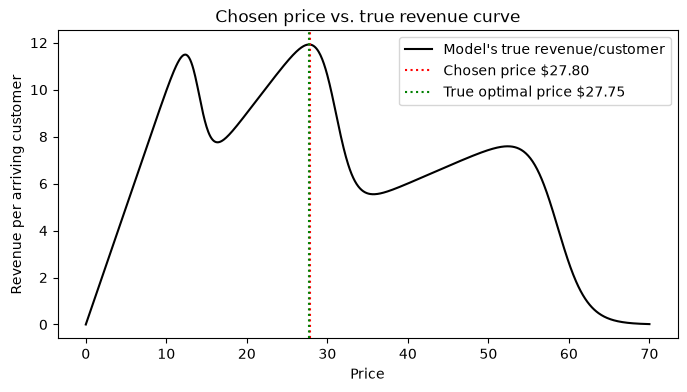

In [14]:
OPTIMAL_PROFIT = 11.925  # expected revenue per customer at the true optimum

print(f"Optimal price found:              ${optimal_price:.2f}")
print(f"Total customers experimented on:  {total_customers:,}")
print(f"Total revenue during experiments: ${total_revenue:,.2f}")
print(f"Revenue per customer:             ${total_revenue / total_customers:.3f}")

# Share of optimal profit captured: our revenue compared with charging
# the optimal price ($11.925 per customer) to every customer we experimented on
pct_captured = 100 * total_revenue / (OPTIMAL_PROFIT * total_customers)
print(f"Share of optimal profit captured: {pct_captured:.1f}%")

# the model's true revenue at the optimal price
true_revenue = optimal_price * purchase_probability(optimal_price)
print(f"True expected revenue at ${optimal_price:.2f}: {true_revenue:.3f} "
      f"({100 * true_revenue / OPTIMAL_PROFIT:.2f}% of optimal)")

# True revenue curve, for comparison only
price_grid = np.linspace(0, 70, 1000)
expected_revenue_per_customer = price_grid * purchase_probability(price_grid)
grid_best_price = price_grid[np.argmax(expected_revenue_per_customer)]

plt.figure(figsize=(8, 4))
plt.plot(price_grid,expected_revenue_per_customer, color="black", label="Model's true revenue/customer")
plt.axvline(optimal_price, color="red", linestyle=":", label=f"Chosen price ${optimal_price:.2f}")
plt.axvline(grid_best_price, color="green", linestyle=":", label=f"True optimal price ${grid_best_price:.2f}")  # best price on the true curve
plt.xlabel("Price")
plt.ylabel("Revenue per arriving customer")
plt.title("Chosen price vs. true revenue curve")
plt.legend()
plt.show()